# Clasificación de cáncer de piel con ResNet-18 — versión mejorada (`_claude`)

Este notebook parte de `1. resnet_18.ipynb` y aplica una serie de mejoras para después **comparar** ambos entrenamientos. Se mantiene la misma red base (ResNet-18 preentrenada en ImageNet), el mismo conjunto de test y el mismo presupuesto total de **20 épocas**, de modo que las diferencias se deban a las mejoras y no a más cómputo.

| # | Mejora | Original | Esta versión |
|---|---|---|---|
| 1 | Optimizador | Adadelta (lr 1.0) | Adam (lr 1e-3 cabeza / 1e-4 fine-tuning) + weight decay |
| 1 | Scheduler | StepLR 2 / 0.5 (lr ≈ 0 en la época 10) | Coseno por fase (baja suave hasta el final) |
| 1 | Congelación | Solo el optimizador ignora el backbone | `requires_grad=False` + BatchNorm del backbone en eval |
| 1 | Batch | 12 | 32 |
| 2 | Data augmentation | Recorte + flip horizontal | Recorte + flips H/V + rotación ±20° + ColorJitter |
| 3 | Entrenamiento | Solo la cabeza, 20 épocas | Fase 1: cabeza (10 ép.) · Fase 2: fine-tuning de `layer4` + cabeza (10 ép.) |
| 4 | Cabeza | Linear 512→2 | Dropout(0.3) + Linear 512→2 |
| 6 | Selección del modelo | Mejor accuracy **en test** | Mejor loss en un **conjunto de validación** separado del train (15%) |
| 6 | Pérdida | CrossEntropy | CrossEntropy con **pesos por clase** |
| 6 | Métricas | Loss y accuracy | + matriz de confusión, sensibilidad, especificidad, AUC |
| — | Parada | Siempre 20 épocas | Early stopping (paciencia 5) en la fase de fine-tuning |

Al final hay una sección que carga las métricas del notebook original (si existen) y dibuja las curvas de ambos juntas.

## 1. Importación de librerías

In [1]:
from pathlib import Path
import json
import time
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import transforms, datasets

## 2. Configuración general

Mismas rutas de datos que el notebook original. Los resultados se guardan en una carpeta distinta (`resultados_resnet18_claude`) para no pisar los del original y poder compararlos.

In [2]:
# Rutas del dataset (idénticas al original)
TRAIN_DIR = Path("./03. skin_cancer/data/train/")
TEST_DIR = Path("./03. skin_cancer/data/test/")

# Resultados de esta versión y del original (para la comparativa final)
OUTPUT_DIR = Path("./03. skin_cancer/resultados_resnet18_claude")
ORIGINAL_DIR = Path("./03. skin_cancer/resultados_resnet18")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hiperparámetros
IMAGE_SIZE = 224
BATCH_SIZE = 32
VAL_FRACTION = 0.15          # parte del train reservada para validación

EPOCHS_HEAD = 10             # fase 1: solo la cabeza
EPOCHS_FINETUNE = 10         # fase 2: layer4 + cabeza  (total = 20, como el original)
LR_HEAD = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.3
PATIENCE = 5                 # early stopping en la fase 2

NUM_WORKERS = 8              # en Windows/Jupyter, si el DataLoader se cuelga, poner 0
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Dispositivo utilizado: {DEVICE}")

Dispositivo utilizado: cuda


## 3. Guardado de la configuración

In [3]:
config = {
    "train_dir": str(TRAIN_DIR), "test_dir": str(TEST_DIR), "output_dir": str(OUTPUT_DIR),
    "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "val_fraction": VAL_FRACTION,
    "epochs_head": EPOCHS_HEAD, "epochs_finetune": EPOCHS_FINETUNE,
    "lr_head": LR_HEAD, "lr_finetune": LR_FINETUNE, "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT, "patience": PATIENCE, "num_workers": NUM_WORKERS,
    "seed": SEED, "device": str(DEVICE),
}
with open(OUTPUT_DIR / "configuracion.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
config

{'train_dir': '03. skin_cancer\\data\\train',
 'test_dir': '03. skin_cancer\\data\\test',
 'output_dir': '03. skin_cancer\\resultados_resnet18_claude',
 'image_size': 224,
 'batch_size': 32,
 'val_fraction': 0.15,
 'epochs_head': 10,
 'epochs_finetune': 10,
 'lr_head': 0.001,
 'lr_finetune': 0.0001,
 'weight_decay': 0.0001,
 'dropout': 0.3,
 'patience': 5,
 'num_workers': 8,
 'seed': 42,
 'device': 'cuda'}

## 4. Transformaciones y aumento de datos (mejora 2)

En entrenamiento se añaden **flip vertical**, **rotación** y **ColorJitter**: en una lesión de piel la orientación no tiene significado, y pequeñas variaciones de luz y color imitan fotos tomadas con distintas cámaras. El enunciado pide expresamente rotaciones y reflexiones.

Validación y test siguen siendo deterministas.

In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transforms_train = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

transforms_eval = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

## 5. Carga del dataset y partición train / validación (mejora 6)

El original elegía el "mejor modelo" mirando el test, lo que infla el resultado final. Aquí se separa un 15% del train como **validación** (estratificado por clase) para elegir el modelo, y el test se reserva para la medición final.

Se crean dos `ImageFolder` sobre la misma carpeta (uno con augmentation y otro sin él) y se reparten los índices con `Subset`, así las imágenes de validación no reciben transformaciones aleatorias.

In [5]:
train_full_aug = datasets.ImageFolder(TRAIN_DIR, transform=transforms_train)
train_full_eval = datasets.ImageFolder(TRAIN_DIR, transform=transforms_eval)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=transforms_eval)

classes = train_full_aug.classes
targets = np.array(train_full_aug.targets)

# Partición estratificada: mismo % de validación en cada clase
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in range(len(classes)):
    idx = np.where(targets == c)[0]
    rng.shuffle(idx)
    n_val = int(round(len(idx) * VAL_FRACTION))
    val_idx.extend(idx[:n_val].tolist())
    train_idx.extend(idx[n_val:].tolist())

train_dataset = Subset(train_full_aug, train_idx)
val_dataset = Subset(train_full_eval, val_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=(DEVICE.type == "cuda"))
train_dataloader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_dataloader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_dataloader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

train_counts = np.bincount(targets[train_idx], minlength=len(classes))
print("Clases:", classes, "| índices:", train_full_aug.class_to_idx)
print("Imágenes -> train:", len(train_dataset), "| validación:", len(val_dataset), "| test:", len(test_dataset))
print("Reparto de clases en train:", dict(zip(classes, train_counts.tolist())))

Clases: ['benign', 'malignant'] | índices: {'benign': 0, 'malignant': 1}
Imágenes -> train: 2241 | validación: 396 | test: 660
Reparto de clases en train: {'benign': 1224, 'malignant': 1017}


## 6. Visualización de imágenes de ejemplo (con el nuevo augmentation)

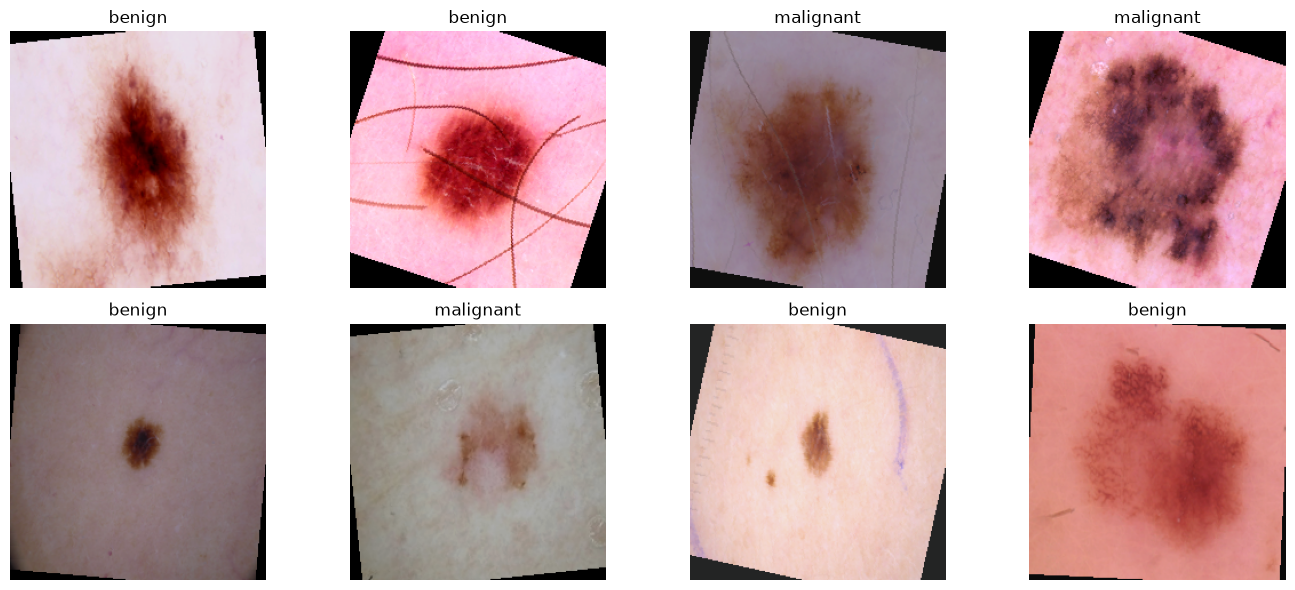

In [6]:
def denormalize_image(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return torch.clamp(tensor.cpu() * std + mean, 0, 1)

images, labels = next(iter(train_dataloader))
plt.figure(figsize=(14, 6))
for i in range(min(8, images.size(0))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalize_image(images[i]).permute(1, 2, 0).numpy())
    plt.title(classes[labels[i].item()])
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ejemplos_dataset.png", dpi=150)
plt.show()

## 7. Modelo: ResNet-18 preentrenada, cabeza nueva y congelación real (mejoras 1 y 4)

- Se carga la ResNet-18 con los pesos por defecto (`DEFAULT`) de ImageNet, como pide el enunciado.
- Se **congela** el backbone con `requires_grad = False`: ya no se calculan sus gradientes (entrenamiento ≈ 3 veces más rápido) y la congelación es explícita.
- La cabeza nueva es `Dropout(0.3) + Linear(512, 2)`: el Dropout apaga al azar el 30% de las 512 características en entrenamiento y reduce el sobreajuste.

In [7]:
try:
    weights = torchvision.models.ResNet18_Weights.DEFAULT
    model = torchvision.models.resnet18(weights=weights)
except AttributeError:
    model = torchvision.models.resnet18(pretrained=True)

num_features = model.fc.in_features
num_classes = len(classes)

model.fc = nn.Sequential(
    nn.Dropout(p=DROPOUT),
    nn.Linear(num_features, num_classes),
)

# Congelamos todo excepto la cabeza
for name, param in model.named_parameters():
    param.requires_grad = name.startswith("fc.")

model = model.to(DEVICE)

def count_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("Características de entrada a la cabeza:", num_features)
print(f"Parámetros entrenables (fase 1): {count_trainable(model):,} de {sum(p.numel() for p in model.parameters()):,}")

Características de entrada a la cabeza: 512
Parámetros entrenables (fase 1): 1,026 de 11,177,538


### Modo train/eval por fase

`model.train()` pone **todas** las BatchNorm en modo entrenamiento, lo que haría que el backbone "congelado" siguiera cambiando sus estadísticas. Esta función deja en modo entrenamiento solo las partes que realmente se entrenan en cada fase.

In [8]:
def set_train_mode(model, trainable_blocks):
    # Todo en eval (BatchNorm con estadísticas fijas) y solo los bloques entrenables en train
    model.eval()
    for block in trainable_blocks:
        getattr(model, block).train()

## 8. Función de pérdida con pesos por clase (mejora 6)

Si hay más imágenes de una clase que de otra, la red tiende a favorecer la mayoritaria. Con `weight` en `CrossEntropyLoss` cada error de la clase minoritaria pesa más. El peso de cada clase es inversamente proporcional a su frecuencia en el train.

El optimizador y el scheduler se crean dentro de cada fase (sección 10).

In [9]:
class_weights = torch.tensor(train_counts.sum() / (len(classes) * train_counts), dtype=torch.float32)
print("Pesos por clase:", dict(zip(classes, class_weights.round(decimals=3).tolist())))

criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))

Pesos por clase: {'benign': 0.9150000214576721, 'malignant': 1.1019999980926514}


## 9. Funciones de entrenamiento y evaluación

Misma lógica que el original. Cambios: `train_one_epoch` recibe qué bloques poner en modo train, y `evaluate` devuelve también la probabilidad de "maligno" para calcular el AUC.

Nota: la loss de validación/test usa los mismos pesos por clase que el entrenamiento, así que no es numéricamente idéntica a la del notebook original. Para comparar ambos notebooks, la referencia más limpia es la **accuracy de test**.

In [10]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, trainable_blocks):
    set_train_mode(model, trainable_blocks)
    running_loss, running_corrects = 0.0, 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        preds = outputs.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += (preds == labels).sum().item()

    n = len(dataloader.dataset)
    return running_loss / n, running_corrects / n * 100


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, running_corrects = 0.0, 0
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            probs = torch.softmax(outputs, dim=1)
            preds = probs.argmax(dim=1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += (preds == labels).sum().item()
            all_labels += labels.cpu().tolist()
            all_preds += preds.cpu().tolist()
            all_probs += probs[:, 1].cpu().tolist()     # probabilidad de la clase 1 (maligno)

    n = len(dataloader.dataset)
    return running_loss / n, running_corrects / n * 100, all_labels, all_preds, all_probs

## 10. Entrenamiento en dos fases (mejoras 1 y 3)

- **Fase 1 (transfer learning):** solo la cabeza, Adam lr 1e-3, scheduler coseno.
- **Fase 2 (fine-tuning):** se descongela `layer4`, el último bloque residual, cuyas características son las más específicas de ImageNet. Se entrena junto a la cabeza con un lr 10 veces menor (1e-4) para no destruir lo aprendido. Hay early stopping si la loss de validación no mejora en 5 épocas.

En cada época se registran train, **validación** (para elegir el modelo) y **test** (solo para comparar con el original; nunca se usa para decidir nada).

In [11]:
history = []
best_val_loss = float("inf")
best_state = None
start_time = time.time()
global_epoch = 0


def run_phase(phase_name, epochs, trainable_blocks, param_groups, patience=None):
    global best_val_loss, best_state, global_epoch
    optimizer = torch.optim.Adam(param_groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    epochs_without_improvement = 0

    for _ in range(epochs):
        global_epoch += 1
        train_loss, train_acc = train_one_epoch(model, train_dataloader, criterion, optimizer, DEVICE, trainable_blocks)
        val_loss, val_acc, *_ = evaluate(model, val_dataloader, criterion, DEVICE)
        test_loss, test_acc, *_ = evaluate(model, test_dataloader, criterion, DEVICE)
        current_lr = optimizer.param_groups[-1]["lr"]
        scheduler.step()
        elapsed = time.time() - start_time

        history.append({
            "epoch": global_epoch, "phase": phase_name,
            "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc,
            "test_loss": test_loss, "test_accuracy": test_acc,
            "learning_rate": current_lr, "elapsed_seconds": elapsed,
        })
        print(f"[{phase_name}] Época {global_epoch:2d} | "
              f"train {train_loss:.4f} / {train_acc:.2f}% | "
              f"val {val_loss:.4f} / {val_acc:.2f}% | "
              f"test {test_loss:.4f} / {test_acc:.2f}% | "
              f"lr {current_lr:.2e} | {elapsed / 60:.1f} min")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            torch.save({"epoch": global_epoch, "model_state_dict": best_state,
                        "class_to_idx": train_full_aug.class_to_idx},
                       OUTPUT_DIR / "mejor_modelo.pt")
            epochs_without_improvement = 0
            print("   -> nuevo mejor modelo (val loss)")
        else:
            epochs_without_improvement += 1

        pd.DataFrame(history).to_csv(OUTPUT_DIR / "metricas_entrenamiento.csv", index=False)

        if patience is not None and epochs_without_improvement >= patience:
            print(f"   Early stopping: {patience} épocas sin mejorar la loss de validación")
            break


# ---- Fase 1: solo la cabeza ----
print(f"Parámetros entrenables fase 1: {count_trainable(model):,}")
run_phase("cabeza", EPOCHS_HEAD, ["fc"],
          [{"params": model.fc.parameters(), "lr": LR_HEAD}])

# ---- Fase 2: fine-tuning de layer4 + cabeza ----
for param in model.layer4.parameters():
    param.requires_grad = True
print(f"Parámetros entrenables fase 2: {count_trainable(model):,}")
run_phase("fine-tuning", EPOCHS_FINETUNE, ["layer4", "fc"],
          [{"params": model.layer4.parameters(), "lr": LR_FINETUNE},
           {"params": model.fc.parameters(), "lr": LR_FINETUNE}],
          patience=PATIENCE)

print(f"Tiempo total de entrenamiento: {(time.time() - start_time) / 60:.2f} minutos")

# Recuperamos el mejor modelo según validación
model.load_state_dict(best_state)

Parámetros entrenables fase 1: 1,026
[cabeza] Época  1 | train 0.5922 / 68.27% | val 0.5920 / 71.72% | test 0.6301 / 71.21% | lr 1.00e-03 | 2.2 min
   -> nuevo mejor modelo (val loss)
[cabeza] Época  2 | train 0.4528 / 79.07% | val 0.4572 / 77.53% | test 0.4870 / 78.79% | lr 9.76e-04 | 3.9 min
   -> nuevo mejor modelo (val loss)
[cabeza] Época  3 | train 0.4381 / 80.99% | val 0.4031 / 81.06% | test 0.4297 / 81.06% | lr 9.05e-04 | 5.3 min
   -> nuevo mejor modelo (val loss)
[cabeza] Época  4 | train 0.4286 / 80.90% | val 0.3891 / 82.58% | test 0.4146 / 81.52% | lr 7.94e-04 | 7.3 min
   -> nuevo mejor modelo (val loss)
[cabeza] Época  5 | train 0.4219 / 81.04% | val 0.3867 / 84.09% | test 0.4107 / 81.82% | lr 6.55e-04 | 8.9 min
   -> nuevo mejor modelo (val loss)
[cabeza] Época  6 | train 0.4166 / 81.17% | val 0.3960 / 82.32% | test 0.4222 / 82.12% | lr 5.00e-04 | 10.6 min
[cabeza] Época  7 | train 0.4152 / 81.04% | val 0.3795 / 85.35% | test 0.4040 / 82.58% | lr 3.45e-04 | 11.9 min
   -

<All keys matched successfully>

## 11. Curvas de entrenamiento

In [12]:
history_df = pd.DataFrame(history)
history_df

,epoch,phase,train_loss,train_accuracy,val_loss,val_accuracy,test_loss,test_accuracy,learning_rate,elapsed_seconds
0,1,cabeza,0.592233,68.273092,0.591982,71.717172,0.630105,71.212121,0.001000,130.052242
1,2,cabeza,0.452806,79.071843,0.457195,77.525253,0.487018,78.787879,0.000976,231.854390
2,3,cabeza,0.438086,80.990629,0.403064,81.060606,0.429726,81.060606,0.000905,320.719287
3,4,cabeza,0.428561,80.901383,0.389107,82.575758,0.414581,81.515152,0.000794,435.711915
4,5,cabeza,0.421860,81.035252,0.386730,84.090909,0.410662,81.818182,0.000655,532.072083
5,6,cabeza,0.416608,81.169121,0.395960,82.323232,0.422173,82.121212,0.000500,633.622941
6,7,cabeza,0.415173,81.035252,0.379494,85.353535,0.403991,82.575758,0.000345,714.002729
7,8,cabeza,0.421194,80.990629,0.365949,86.868687,0.386136,82.727273,0.000206,791.310403
8,9,cabeza,0.397156,81.838465,0.367491,86.111111,0.388821,82.878788,0.000095,909.378148
9,10,cabeza,0.396140,81.079875,0.370532,86.111111,0.393066,82.878788,0.000024,997.414749


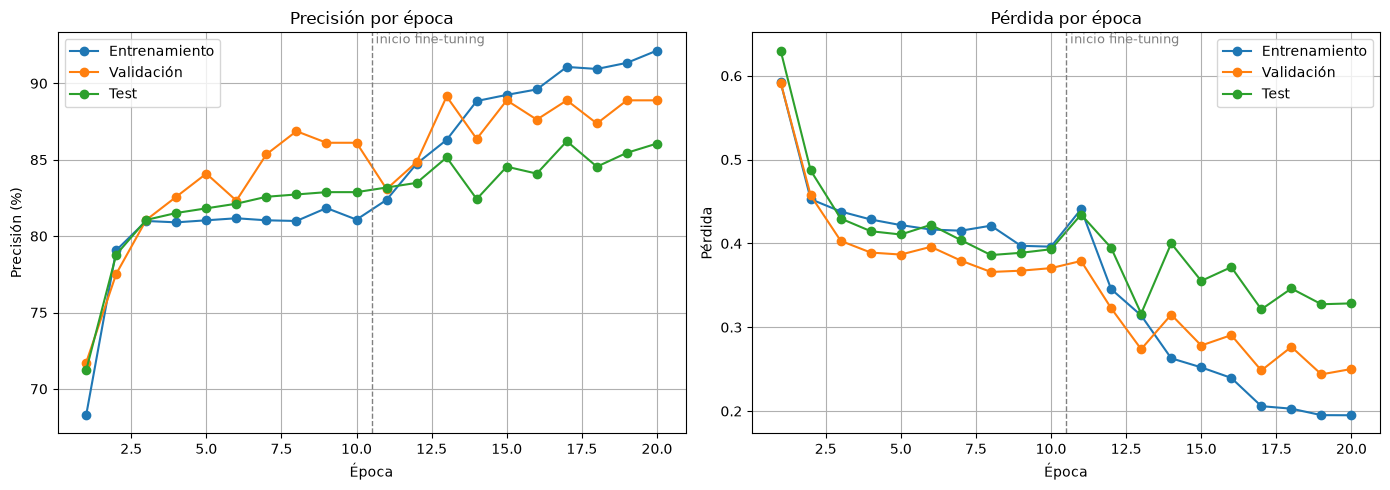

In [13]:
fase2_inicio = EPOCHS_HEAD + 0.5
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, ylabel in [(axes[0], "accuracy", "Precisión (%)"), (axes[1], "loss", "Pérdida")]:
    for split, label in [("train", "Entrenamiento"), ("val", "Validación"), ("test", "Test")]:
        ax.plot(history_df["epoch"], history_df[f"{split}_{metric}"], marker="o", label=label)
    ax.axvline(fase2_inicio, color="gray", linestyle="--", linewidth=1)
    ax.text(fase2_inicio, ax.get_ylim()[1], " inicio fine-tuning", va="top", fontsize=9, color="gray")
    ax.set_xlabel("Época"); ax.set_ylabel(ylabel); ax.grid(True); ax.legend()
axes[0].set_title("Precisión por época"); axes[1].set_title("Pérdida por época")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curvas_entrenamiento.png", dpi=150)
plt.show()

## 12. Evaluación final en test: matriz de confusión y métricas clínicas (mejora 6)

Con el mejor modelo (elegido por validación) se mide una sola vez sobre el test.

- **Sensibilidad (recall de maligno):** de los malignos reales, cuántos detecta. Es la métrica crítica, porque un falso negativo es un cáncer no detectado.
- **Especificidad:** de los benignos reales, cuántos identifica como benignos.
- **AUC:** capacidad de separar ambas clases con cualquier umbral (1 = perfecta, 0,5 = azar).

               test_loss: 0.33
           test_accuracy: 85.45
    sensibilidad_maligno: 82.67
   especificidad_benigno: 87.78
       precision_maligno: 84.93
                     auc: 0.95
                      TN: 316
                      FP: 44
                      FN: 52
                      TP: 248


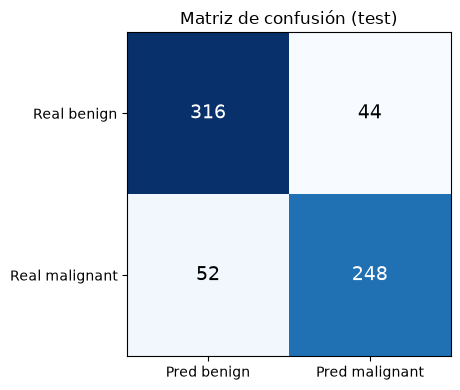

In [14]:
def auc_score(y_true, scores):
    # AUC = probabilidad de que un maligno tenga más score que un benigno (Mann-Whitney)
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    pos, neg = scores[y_true == 1], scores[y_true == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    order = np.argsort(np.concatenate([pos, neg]))
    ranks = np.empty(len(order)); ranks[order] = np.arange(1, len(order) + 1)
    all_scores = np.concatenate([pos, neg])
    for s in np.unique(all_scores):            # empates: rango medio
        m = all_scores == s
        ranks[m] = ranks[m].mean()
    return (ranks[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))


test_loss, test_acc, y_true, y_pred, y_prob = evaluate(model, test_dataloader, criterion, DEVICE)
y_true, y_pred = np.array(y_true), np.array(y_pred)

tn = int(((y_true == 0) & (y_pred == 0)).sum()); fp = int(((y_true == 0) & (y_pred == 1)).sum())
fn = int(((y_true == 1) & (y_pred == 0)).sum()); tp = int(((y_true == 1) & (y_pred == 1)).sum())

final_metrics = {
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "sensibilidad_maligno": tp / (tp + fn) * 100 if (tp + fn) else float("nan"),
    "especificidad_benigno": tn / (tn + fp) * 100 if (tn + fp) else float("nan"),
    "precision_maligno": tp / (tp + fp) * 100 if (tp + fp) else float("nan"),
    "auc": auc_score(y_true, y_prob),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
}
with open(OUTPUT_DIR / "metricas_finales.json", "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=4)

for k, v in final_metrics.items():
    print(f"{k:>24}: {v:.2f}" if isinstance(v, float) else f"{k:>24}: {v}")

cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels([f"Pred {c}" for c in classes])
ax.set_yticks([0, 1]); ax.set_yticklabels([f"Real {c}" for c in classes])
ax.set_title("Matriz de confusión (test)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "matriz_confusion.png", dpi=150)
plt.show()

## 13. Predicciones de ejemplo

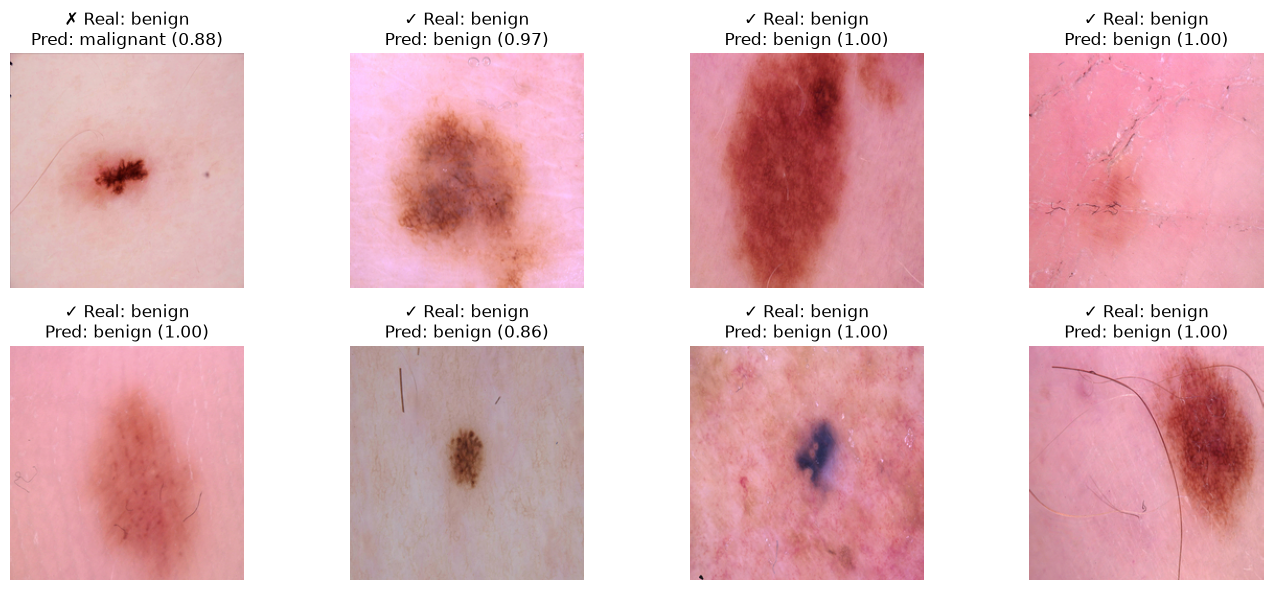

In [15]:
def predict_batch(model, dataloader, device):
    model.eval()
    inputs, labels = next(iter(dataloader))
    with torch.no_grad():
        probabilities = torch.softmax(model(inputs.to(device)), dim=1)
        confidences, preds = torch.max(probabilities, 1)
    return inputs, labels, preds.cpu(), confidences.cpu()

images, labels, preds, confidences = predict_batch(model, test_dataloader, DEVICE)
plt.figure(figsize=(14, 6))
for i in range(min(8, images.size(0))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalize_image(images[i]).permute(1, 2, 0).numpy())
    ok = "✓" if preds[i] == labels[i] else "✗"
    plt.title(f"{ok} Real: {classes[labels[i]]}\nPred: {classes[preds[i]]} ({confidences[i]:.2f})")
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "predicciones_ejemplo.png", dpi=150)
plt.show()

## 14. Comparativa con el notebook original

Carga `metricas_entrenamiento.csv` de la carpeta del original (hay que haberlo ejecutado antes) y compara las curvas de **test** época a época, además de una tabla resumen.

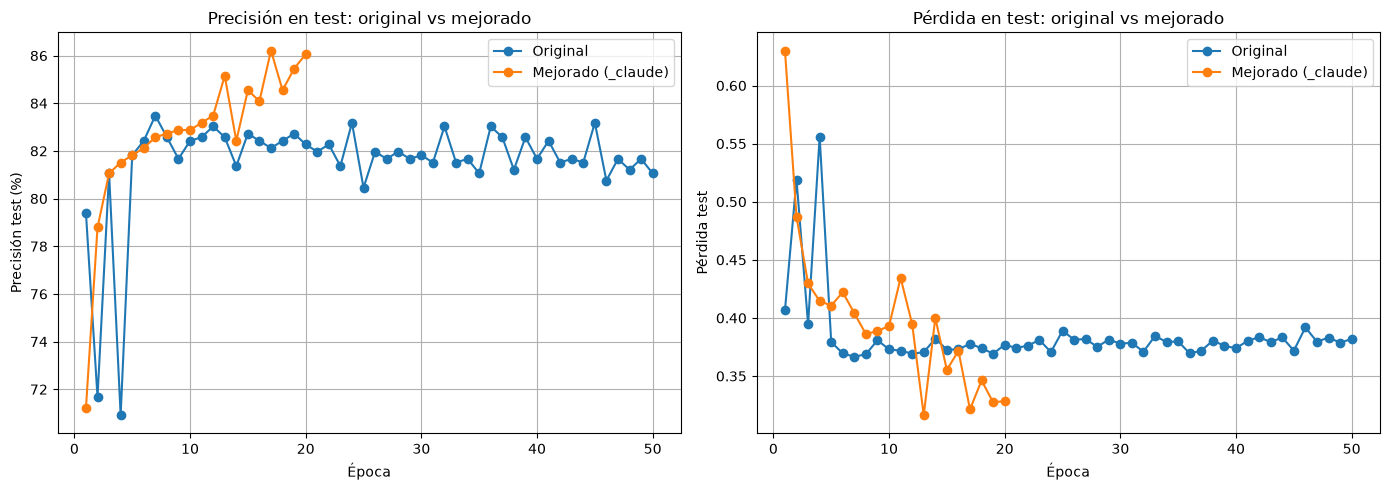

,Original,Mejorado (_claude)
Accuracy test final (%),81.06,85.45
Accuracy test máxima (%),83.48,86.21
Hueco train-test final (pp),2.37,6.09
Tiempo (min),38.94,27.03


Nota: 'Accuracy test máxima' del original está elegida mirando el test (optimista); en la versión mejorada el modelo final se elige por validación.


In [16]:
original_csv = ORIGINAL_DIR / "metricas_entrenamiento.csv"

if original_csv.exists():
    orig = pd.read_csv(original_csv)
    new = history_df

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, metric, ylabel in [(axes[0], "test_accuracy", "Precisión test (%)"), (axes[1], "test_loss", "Pérdida test")]:
        ax.plot(orig["epoch"], orig[metric], marker="o", label="Original")
        ax.plot(new["epoch"], new[metric], marker="o", label="Mejorado (_claude)")
        ax.set_xlabel("Época"); ax.set_ylabel(ylabel); ax.grid(True); ax.legend()
    axes[0].set_title("Precisión en test: original vs mejorado")
    axes[1].set_title("Pérdida en test: original vs mejorado")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "comparativa_original_vs_mejorado.png", dpi=150)
    plt.show()

    resumen = pd.DataFrame({
        "Original": {
            "Accuracy test final (%)": orig["test_accuracy"].iloc[-1],
            "Accuracy test máxima (%)": orig["test_accuracy"].max(),
            "Hueco train-test final (pp)": orig["train_accuracy"].iloc[-1] - orig["test_accuracy"].iloc[-1],
            "Tiempo (min)": orig["elapsed_seconds"].iloc[-1] / 60,
        },
        "Mejorado (_claude)": {
            "Accuracy test final (%)": final_metrics["test_accuracy"],
            "Accuracy test máxima (%)": new["test_accuracy"].max(),
            "Hueco train-test final (pp)": new["train_accuracy"].iloc[-1] - new["test_accuracy"].iloc[-1],
            "Tiempo (min)": new["elapsed_seconds"].iloc[-1] / 60,
        },
    }).round(2)
    resumen.to_csv(OUTPUT_DIR / "comparativa_resumen.csv")
    display(resumen)
    print("Nota: 'Accuracy test máxima' del original está elegida mirando el test (optimista); "
          "en la versión mejorada el modelo final se elige por validación.")
else:
    print(f"No se encontró {original_csv}. Ejecuta primero '1. resnet_18.ipynb' para poder comparar.")

## 15. Guardado final del modelo

In [17]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_full_aug.class_to_idx,
    "classes": classes,
    "history": history,
    "config": config,
    "final_metrics": final_metrics,
}, OUTPUT_DIR / "modelo_final.pt")

print("Modelo final (mejor por validación):", OUTPUT_DIR / "modelo_final.pt")
print("Métricas por época:", OUTPUT_DIR / "metricas_entrenamiento.csv")
print("Métricas finales:", OUTPUT_DIR / "metricas_finales.json")

Modelo final (mejor por validación): 03. skin_cancer\resultados_resnet18_claude\modelo_final.pt
Métricas por época: 03. skin_cancer\resultados_resnet18_claude\metricas_entrenamiento.csv
Métricas finales: 03. skin_cancer\resultados_resnet18_claude\metricas_finales.json


## 16. Comentario final

Las mejoras atacan los tres problemas que se veían en el original:

1. **El entrenamiento se paraba solo:** el StepLR dejaba el lr casi a cero en la época 10. Ahora Adam con scheduler coseno aprovecha las 20 épocas.
2. **Sobreajuste:** más data augmentation y Dropout en la cabeza. El fine-tuning se limita a `layer4` y usa un lr bajo.
3. **Evaluación optimista:** el modelo se elige con validación y se añaden métricas clínicas (sensibilidad, especificidad, AUC), más adecuadas que la accuracy para un problema médico.

Próximos pasos posibles: descongelar más bloques (`layer3`), probar ResNet-50 o EfficientNet, ajustar el umbral de decisión para priorizar la sensibilidad, test-time augmentation y Grad-CAM para ver en qué zona de la lesión se fija la red.